In [1]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/boat_vs_noise_audio_products.csv")

In [3]:
df.shape

(518, 28)

In [4]:
df.head()

,product_id,brand,category,sale_price,mrp,discount_percent,num_variants,edition_type,model_series,year,...,playtime,ip_rating,latency,fast_charge,connectivity,gaming_mode,rating,battery_capacity,base_model,price_tier
0,6.630000e+12,boAt,True Wireless Earbuds,1599,2990,46.52,1,Franchise,Airdopes,2021,...,60.0,IPX4,50.0,True,Single,False,4.9,650,airdopes 131,Mid
1,6.630000e+12,boAt,Headphones,1799,3990,54.91,1,Franchise,Rockerz,2021,...,15.0,NaN,45.0,False,Dual,False,4.9,300,rockerz 450,Mid
2,6.630000e+12,boAt,Headphones,1799,3990,54.91,1,Franchise,Rockerz,2021,...,15.0,NaN,45.0,False,Dual,False,4.7,300,rockerz 450,Mid
3,6.810000e+12,boAt,True Wireless Earbuds,1099,3490,68.51,3,Standard,Airdopes,2022,...,50.0,IPX4,50.0,True,Single,True,4.7,320,airdopes 100,Budget
4,6.570000e+12,boAt,True Wireless Earbuds,1199,2990,59.90,2,Standard,Airdopes,2021,...,15.0,IPX4,50.0,False,Single,False,4.9,650,airdopes 101,Budget


In [5]:
df['sale_price'].describe()

count     518.000000
mean     1639.129344
std       945.551399
min       249.000000
25%      1099.000000
50%      1399.000000
75%      1899.000000
max      6499.000000
Name: sale_price, dtype: float64

In [6]:
df['sale_price'].isna().sum()

np.int64(0)

In [7]:
df['sale_price'].dtype

dtype('int64')

In [8]:
population_mean = df['sale_price'].mean()
population_std = df['sale_price'].std(ddof=0)
population_n = df['sale_price'].count()

population_mean, population_std, population_n

(np.float64(1639.1293436293436), np.float64(944.6382633162765), np.int64(518))

Step 1 — Frame the Statistical Question - 
Our dataset contains the sale_price of audio products.

Question:
Is the average sale price of audio products significantly different from ₹2,500?

We want to use a sample of products to determine whether the population mean sale price differs significantly from ₹2,500.

Step 2 — Select the Appropriate Statistical Test
Our objective is to compare:
- One numerical variable: sale_price
- Sample mean: x̄
- Hypothesized population mean: μ₀ = ₹2,500
A one-sample Z-test for a population mean is appropriate when the population standard deviation σ is known.
For this project, we will treat the population standard deviation calculated from the complete dataset as known for educational/simulation purposes.
The sample size will also be sufficiently large (n = 50), supporting the normal approximation of the sampling distribution of the mean.
Therefore, we will use a one-sample two-tailed Z-test for the population mean.

Step 3 — Check the Assumptions
1. Independence of observations
Each product should represent an independent observation.
We should also avoid treating repeated records of the same product as independent observations.

2. Random sampling
We will randomly select 50 products from the dataset:

In [10]:
sample = df['sale_price'].sample(n=50, random_state=42)

sample_mean = sample.mean()
sample_n = sample.count()

sample_mean, sample_n

(np.float64(1856.78), np.int64(50))

3. Numerical variable
sale_price is a quantitative numerical variable.

In [11]:
df['sale_price'].dtype

dtype('int64')

4. Population standard deviation is known

In [12]:
population_std = df['sale_price'].std(ddof=0)

5. Sampling distribution of the mean should be approximately normal

In [13]:
sample_n

np.int64(50)

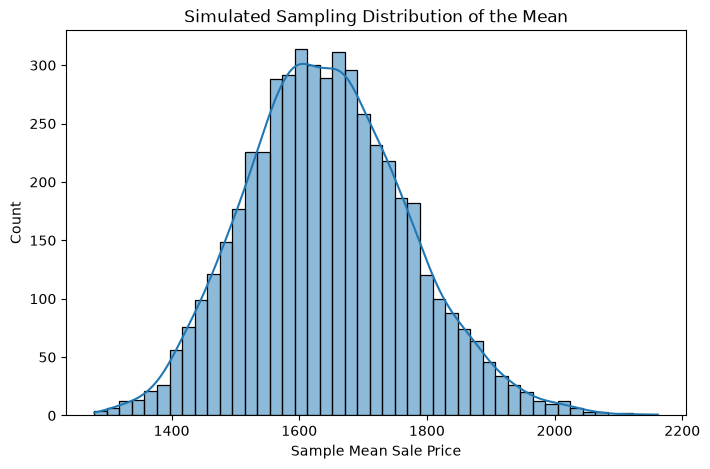

In [16]:
sample_means = []

for _ in range(5000):
    sample = df['sale_price'].sample(n=50)
    sample_means.append(sample.mean())
plt.figure(figsize=(8, 5))
sns.histplot(sample_means, kde=True)
plt.xlabel("Sample Mean Sale Price")
plt.title("Simulated Sampling Distribution of the Mean")
plt.show()

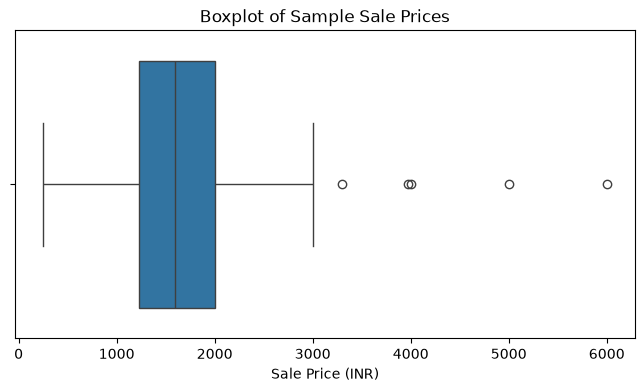

In [15]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=sample)
plt.xlabel("Sale Price (INR)")
plt.title("Boxplot of Sample Sale Prices")
plt.show()

The outliers are genuine values 

### Hypotheses

We want to test whether the population mean sale price of audio products
is significantly different from ₹2,500.

H₀: μ = ₹2,500

H₁: μ ≠ ₹2,500

This is a two-tailed hypothesis test.

### Significance Level

α = 0.05

Therefore, the critical Z-values are:
−1.96 and +1.96
So the rejection region is: Z < -1.96  or Z > 1.96


Step 6 — Now calculate the Z-statistic

In [17]:
mu_0 = 2500
alpha = 0.05

z_stat = (sample_mean - mu_0) / (population_std / np.sqrt(sample_n))

z_stat

np.float64(-4.814808392347856)

In [18]:
p_value = 2 * stats.norm.sf(abs(z_stat))

p_value

np.float64(1.473411968765976e-06)

Step 7 — Make the Statistical Decision

In [19]:
if p_value <= alpha:
    decision = "Reject H₀"
else:
    decision = "Fail to reject H₀"

decision

'Reject H₀'

In [20]:
population_mean = df['sale_price'].mean()

In [22]:
print(f"Hypothesized Mean: ₹{mu_0:.2f}")
print(f"Sample Mean: ₹{sample_mean:.2f}")
print(f"Actual Population Mean: ₹{population_mean:.2f}")

Hypothesized Mean: ₹2500.00
Sample Mean: ₹1856.78
Actual Population Mean: ₹1639.13


Validation: Since the complete dataset is available for this educational analysis, the actual population mean is ₹1,639.13, which differs substantially from the hypothesized mean of ₹2,500. Therefore, the observed rejection of H₀ is consistent with the known population mean. In a real-world hypothesis-testing scenario, the true population mean would generally be unknown

In [3]:
cohens_d = (1856.78 - 2500) / 1639.13

print("Cohen's d:", cohens_d)

Cohen's d: -0.39241548870437365


In [4]:
from statsmodels.stats.power import NormalIndPower

analysis = NormalIndPower()

n = analysis.solve_power(
    effect_size=0.4,
    alpha=0.05,
    power=0.80,
    alternative="two-sided"
)

print(n)

98.11075664775183


In [2]:
from scipy.stats import norm
import numpy as np
delta = 0.4 * np.sqrt(518)

norm.cdf(-1.96 - delta) + 1 - norm.cdf(1.96 - delta)


np.float64(0.9999999999995463)

In [4]:
from scipy.stats import norm
import numpy as np

n = 518
alpha = 0.05
power = 0.80
population_std=945.55
z_alpha = norm.ppf(1 - alpha/2)
z_power = norm.ppf(power)

MDE = (z_alpha + z_power) * population_std / np.sqrt(n)

print("MDE:", MDE)

MDE: 116.39208723998073


here the minimun detectable effect is 116 which means with power of 80% and sample size of 518 and std dev as mentioned the difference from the real population mean at 116 on both the sides can be detected with 80% power , more diff -> power becomes more and vice a versa

In [7]:
z_critical = norm.ppf(1 - alpha/2)

margin_error = z_critical * population_std / np.sqrt(518)
sample_mean=1856
lower = sample_mean - margin_error
upper = sample_mean + margin_error

In [8]:
print("95% CI:", (lower, upper))

95% CI: (np.float64(1774.57313580864), np.float64(1937.42686419136))
